# Low Level Design — From Boxes to Code

## What is LLD?

HLD draws the boxes. **LLD fills the boxes with contracts.**

When HLD says *"we need a model server"*, LLD answers:
- What **classes** does it have?
- What **API endpoints** does it expose?
- What **data schemas** flow in and out?
- What **design patterns** structure the internals?

LLD is the bridge between the whiteboard and a pull request. A good LLD means engineers can start coding independently and their work will fit together.

> **Real-world flow:** HLD (system design review) → LLD (tech spec / RFC) → Code review → Merge

In [1]:
from dataclasses import dataclass, field
from typing import Optional, Dict, List, Any
from enum import Enum
import time

# ── Data schemas: the contract between client and server ─────────────────────

class ModelStatus(Enum):
    LOADING  = "loading"
    READY    = "ready"
    FAILED   = "failed"

@dataclass
class PredictionRequest:
    """Incoming request to the model server."""
    features:    Dict[str, Any]          # feature name → value
    model_name:  str        = "default"
    model_version: Optional[str] = None  # None = latest
    request_id:  str        = field(default_factory=lambda: str(time.time_ns()))

@dataclass
class PredictionResponse:
    """Response from the model server."""
    prediction:  Any
    confidence:  Optional[float]
    model_name:  str
    model_version: str
    latency_ms:  float
    request_id:  str

class ModelServer:
    """Core serving component. Loads models and handles prediction requests."""

    def __init__(self):
        self._models: Dict[str, Any] = {}   # name:version → loaded model
        self._status: Dict[str, ModelStatus] = {}

    def load_model(self, name: str, version: str, path: str) -> None:
        """Load a model artifact into memory."""
        self._status[f"{name}:{version}"] = ModelStatus.LOADING
        # In production: deserialize from model registry (S3, MLflow, etc.)
        self._models[f"{name}:{version}"] = {"name": name, "version": version, "path": path}
        self._status[f"{name}:{version}"] = ModelStatus.READY
        print(f"✓ Loaded {name}:{version} from {path}")

    def predict(self, request: PredictionRequest) -> PredictionResponse:
        """Run inference and return a structured response."""
        start = time.perf_counter()
        version = request.model_version or "v1"
        key = f"{request.model_name}:{version}"

        if key not in self._models:
            raise ValueError(f"Model {key} not loaded")

        # Simulate inference
        prediction = sum(request.features.values()) % 2
        confidence = 0.87
        latency_ms = (time.perf_counter() - start) * 1000

        return PredictionResponse(
            prediction=prediction, confidence=confidence,
            model_name=request.model_name, model_version=version,
            latency_ms=round(latency_ms, 3), request_id=request.request_id
        )

# Demo
server = ModelServer()
server.load_model("fraud-detector", "v1", "s3://models/fraud-detector-v1.pkl")

req = PredictionRequest(
    features={"amount": 1500.0, "hour": 3, "country_code": 44},
    model_name="fraud-detector",
    model_version="v1",
)
resp = server.predict(req)
print(f"\nPrediction: {resp.prediction}")
print(f"Confidence: {resp.confidence}")
print(f"Latency:    {resp.latency_ms}ms")
print(f"Request ID: {resp.request_id}")

✓ Loaded fraud-detector:v1 from s3://models/fraud-detector-v1.pkl

Prediction: 1.0
Confidence: 0.87
Latency:    0.022ms
Request ID: 1782737053517347557


## API Design for ML Services

### REST vs gRPC
| Dimension | REST (HTTP/JSON) | gRPC (HTTP/2 + Protobuf) |
|-----------|-----------------|-------------------------|
| **Latency** | Higher (text JSON) | Lower (binary protobuf) |
| **Human readable** | Yes | No (binary) |
| **Streaming** | Polling/SSE | Native bidirectional |
| **Tooling** | Universal (curl, Postman) | Requires gRPC client |
| **Best for** | External APIs, dashboards | Internal microservice calls |

**Recommendation:** REST for external-facing APIs. gRPC for high-throughput internal calls (feature server → model server).

### Endpoint Design Conventions
```
POST   /v1/predict          → run inference
POST   /v1/predict/batch    → batch inference
GET    /v1/models           → list available models
GET    /v1/models/{name}    → model metadata
GET    /v1/health/live      → is process alive? (liveness)
GET    /v1/health/ready     → is model loaded? (readiness)
GET    /v1/metrics          → Prometheus metrics
```

### Status Codes for ML APIs
- `200 OK` — prediction returned
- `400 Bad Request` — missing/invalid features
- `404 Not Found` — model name doesn't exist
- `503 Service Unavailable` — model still loading or GPU OOM

In [2]:
# FastAPI route definitions — the API contract as code
# (Pattern demonstration — no server started)

api_contract = """
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Dict, Any, Optional, List

app = FastAPI(title="ML Model Server", version="1.0.0")

class PredictRequest(BaseModel):
    features: Dict[str, Any]
    model_name: str = "default"
    model_version: Optional[str] = None

class PredictResponse(BaseModel):
    prediction: Any
    confidence: float
    model_version: str
    latency_ms: float

@app.post("/v1/predict", response_model=PredictResponse)
async def predict(request: PredictRequest):
    # Validate features exist
    if not request.features:
        raise HTTPException(status_code=400, detail="features cannot be empty")
    # Run inference
    result = model_server.predict(request)
    return PredictResponse(**result)

@app.get("/v1/models")
async def list_models() -> List[Dict]:
    return model_server.list_models()

@app.get("/v1/health/ready")
async def readiness():
    if not model_server.is_ready():
        raise HTTPException(status_code=503, detail="model not loaded")
    return {"status": "ready"}
"""

print("API Contract (FastAPI):")
print(api_contract)

API Contract (FastAPI):

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Dict, Any, Optional, List

app = FastAPI(title="ML Model Server", version="1.0.0")

class PredictRequest(BaseModel):
    features: Dict[str, Any]
    model_name: str = "default"
    model_version: Optional[str] = None

class PredictResponse(BaseModel):
    prediction: Any
    confidence: float
    model_version: str
    latency_ms: float

@app.post("/v1/predict", response_model=PredictResponse)
async def predict(request: PredictRequest):
    # Validate features exist
    if not request.features:
        raise HTTPException(status_code=400, detail="features cannot be empty")
    # Run inference
    result = model_server.predict(request)
    return PredictResponse(**result)

@app.get("/v1/models")
async def list_models() -> List[Dict]:
    return model_server.list_models()

@app.get("/v1/health/ready")
async def readiness():
    if not model_server.is_ready():
        rai

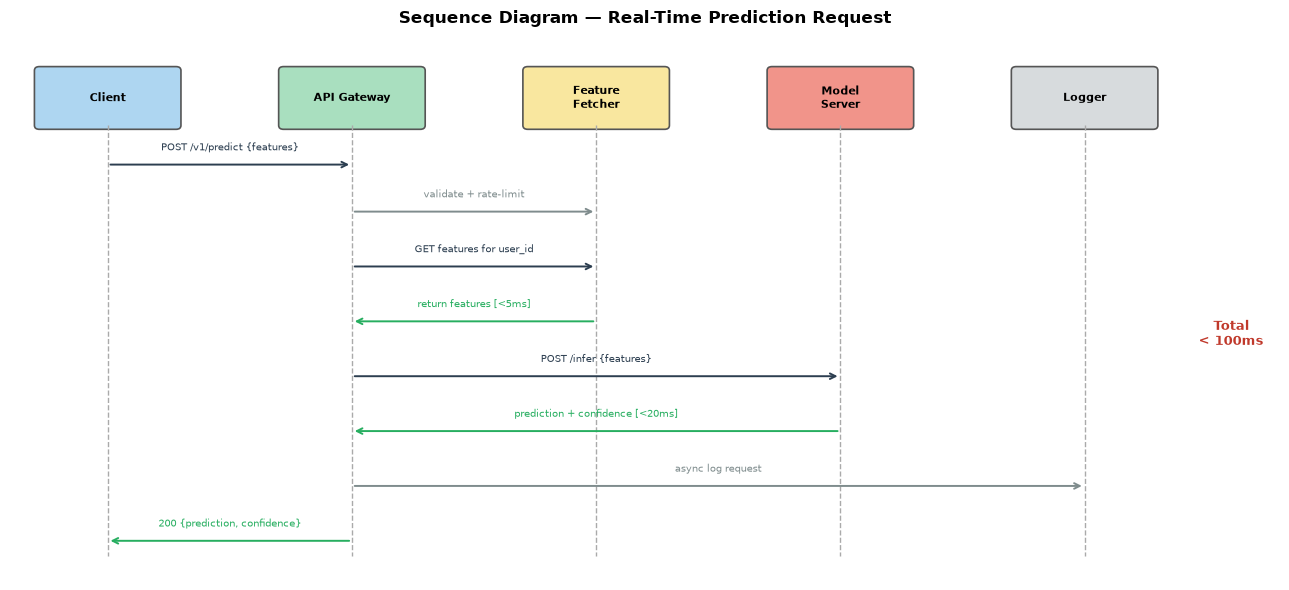

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Sequence diagram: prediction request flow
fig, ax = plt.subplots(figsize=(13, 6))
ax.set_xlim(0, 13); ax.set_ylim(0, 7); ax.axis('off')
ax.set_title('Sequence Diagram — Real-Time Prediction Request', fontsize=12, fontweight='bold')

actors = [(1,'Client'), (3.5,'API Gateway'), (6,'Feature\nFetcher'), (8.5,'Model\nServer'), (11,'Logger')]
colors = ['#AED6F1','#A9DFBF','#F9E79F','#F1948A','#D7DBDD']

for (x,name), color in zip(actors, colors):
    ax.add_patch(mpatches.FancyBboxPatch((x-0.7,5.8),1.4,0.7,
        boxstyle='round,pad=0.05',facecolor=color,edgecolor='#555',lw=1.2))
    ax.text(x,6.15,name,ha='center',va='center',fontsize=8,fontweight='bold')
    ax.plot([x,x],[5.8,0.3],'--',color='#aaa',lw=1)

msgs = [
    (1,3.5,5.3,'POST /v1/predict {features}','→','#2c3e50'),
    (3.5,6.0,4.7,'validate + rate-limit','→','#7f8c8d'),
    (3.5,6.0,4.0,'GET features for user_id','→','#2c3e50'),
    (6.0,3.5,3.3,'return features [<5ms]','←','#27ae60'),
    (3.5,8.5,2.6,'POST /infer {features}','→','#2c3e50'),
    (8.5,3.5,1.9,'prediction + confidence [<20ms]','←','#27ae60'),
    (3.5,11.0,1.2,'async log request','→','#7f8c8d'),
    (3.5,1.0,0.5,'200 {prediction, confidence}','←','#27ae60'),
]
for x1,x2,y,label,direction,color in msgs:
    ax.annotate('',xy=(x2,y),xytext=(x1,y),
        arrowprops=dict(arrowstyle='->',color=color,lw=1.4))
    mx = (x1+x2)/2
    ax.text(mx,y+0.15,label,ha='center',va='bottom',fontsize=7.5,color=color)

ax.text(12.5,3.0,'Total\n< 100ms',ha='center',fontsize=9,color='#c0392b',fontweight='bold')
plt.tight_layout(); plt.show()

## Data Modeling — ML Entities

Every ML system has the same core entities. LLD defines their schemas precisely:

| Entity | Key Fields | Relationships |
|--------|-----------|---------------|
| **Experiment** | id, name, created_at, owner | has many Runs |
| **Run** | id, experiment_id, status, start_time, end_time | belongs to Experiment, has many Metrics & Artifacts |
| **Metric** | id, run_id, name, value, step, timestamp | belongs to Run |
| **Artifact** | id, run_id, type, path, size_bytes | belongs to Run |
| **Model** | id, name, run_id, stage, version | points to an Artifact |

In [4]:
# SQLAlchemy-style ORM definitions — the data model as code
from dataclasses import dataclass, field
from typing import Optional, List
from datetime import datetime
from enum import Enum

class RunStatus(Enum):
    RUNNING   = "running"
    COMPLETED = "completed"
    FAILED    = "failed"

class ModelStage(Enum):
    STAGING    = "staging"
    PRODUCTION = "production"
    ARCHIVED   = "archived"

@dataclass
class Experiment:
    id: int
    name: str
    description: Optional[str] = None
    created_at: datetime = field(default_factory=datetime.now)
    tags: dict = field(default_factory=dict)

@dataclass
class Run:
    id: int
    experiment_id: int          # FK → Experiment.id
    status: RunStatus = RunStatus.RUNNING
    start_time: datetime = field(default_factory=datetime.now)
    end_time: Optional[datetime] = None
    params: dict = field(default_factory=dict)

@dataclass
class Metric:
    id: int
    run_id: int                 # FK → Run.id
    name: str                   # e.g. "accuracy", "loss", "f1"
    value: float
    step: int = 0
    timestamp: datetime = field(default_factory=datetime.now)

@dataclass
class Artifact:
    id: int
    run_id: int                 # FK → Run.id
    artifact_type: str          # "model", "plot", "dataset"
    path: str                   # s3://bucket/path or local
    size_bytes: int = 0

# Instantiate and show
exp = Experiment(id=1, name="fraud-detection-v2", tags={"team": "risk"})
run = Run(id=101, experiment_id=1, params={"lr": 0.001, "n_estimators": 100})
metrics = [Metric(id=i, run_id=101, name="accuracy", value=0.91+i*0.002, step=i) for i in range(3)]

print(f"Experiment: {exp.name} (id={exp.id})")
print(f"Run: {run.id} | params: {run.params}")
for m in metrics:
    print(f"  Metric[step={m.step}]: {m.name} = {m.value:.4f}")

Experiment: fraud-detection-v2 (id=1)
Run: 101 | params: {'lr': 0.001, 'n_estimators': 100}
  Metric[step=0]: accuracy = 0.9100
  Metric[step=1]: accuracy = 0.9120
  Metric[step=2]: accuracy = 0.9140


## Design Patterns in ML Systems

| Pattern | What It Does | ML Use Case |
|---------|-------------|-------------|
| **Factory** | Creates objects without specifying exact class | `ModelFactory.load("xgboost")` — returns correct model type |
| **Strategy** | Swap algorithms at runtime | Choose inference backend (ONNX, TorchScript, sklearn) |
| **Observer** | Notify listeners on events | Log predictions, trigger alerts on model drift |
| **Repository** | Abstract data access | `RunRepository.get_best_run()` — hides SQL details |

In [5]:
from abc import ABC, abstractmethod
import numpy as np

# Strategy Pattern — swap inference backends without changing the caller
class InferenceStrategy(ABC):
    @abstractmethod
    def predict(self, features: np.ndarray) -> np.ndarray: ...
    @abstractmethod
    def name(self) -> str: ...

class SklearnStrategy(InferenceStrategy):
    def predict(self, features):
        return (features.sum(axis=1) > 0).astype(int)  # simulate sklearn predict
    def name(self): return "sklearn"

class ONNXStrategy(InferenceStrategy):
    def predict(self, features):
        return (features.mean(axis=1) > 0.5).astype(int)  # simulate ONNX runtime
    def name(self): return "onnx"

class ModelRunner:
    """Caller doesn't know or care which backend is being used."""
    def __init__(self, strategy: InferenceStrategy):
        self._strategy = strategy

    def run(self, features: np.ndarray) -> np.ndarray:
        print(f"Running inference with: {self._strategy.name()}")
        return self._strategy.predict(features)

    def switch_backend(self, strategy: InferenceStrategy):
        print(f"Switching from {self._strategy.name()} → {strategy.name()}")
        self._strategy = strategy

X = np.array([[0.1, 0.9, -0.2], [0.5, 0.3, 0.8], [-0.3, -0.1, -0.5]])

runner = ModelRunner(SklearnStrategy())
print("Predictions:", runner.run(X))

runner.switch_backend(ONNXStrategy())
print("Predictions:", runner.run(X))

Running inference with: sklearn
Predictions: [1 1 0]
Switching from sklearn → onnx
Running inference with: onnx
Predictions: [0 1 0]


## Key Takeaways

1. **LLD makes implicit decisions explicit** — if it's not written down, two engineers will make different assumptions
2. **Dataclasses/Pydantic are LLD artifacts** — your schema definitions ARE the specification
3. **Good API design = good LLD** — versioning, clear request/response schemas, meaningful status codes
4. **Design patterns reduce surprise** — every engineer knows what a Strategy, Factory, or Observer means
5. **LLD happens before code, not during** — a PR is too late to redesign the interface

### Additional Learning Resources
- *Clean Architecture* — Robert C. Martin
- *Patterns of Enterprise Application Architecture* — Martin Fowler
- FastAPI docs: https://fastapi.tiangolo.com
- Google API Design Guide: https://cloud.google.com/apis/design